In [2]:
%pip install torch torchvision numpy matplotlib

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 1.3/126.7 MB 3.3 MB/s eta 0:00:38
    --------------------------------------- 2.4/126.7 MB 3.9 MB/s eta 0:00:32
    --------------------------------------- 3.1/126.7 MB 4.0 MB/s eta 0:00:31
   - -------------------------------------- 3.9/126.7 MB 3.9 MB/s eta 0:00:32
   - -------------------------------------- 4.2/126.7 MB 3.4 MB/s eta 0:00:36
   - -------------------------------------- 5.8/126.7 MB 4.1 MB/s eta 0:00:30
   -- ------------------------------------- 6.6/126.7 MB 4.0 MB/s eta 0:00:30
   -- ------------------------------------- 7.3/126.7 MB 4.0 MB/s eta 0:00:30
   -- ------------------------------------- 8.1/126.7 MB 4.0 MB/s eta 0:00:30
   -- ------------------------------------- 8.9/126.7 MB 4.0 MB/s eta 0:00:30
   --- ------------------------------------ 9.7/126.7 MB 4.0 MB/s eta 0:00:30


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pptagent 1.1.37 requires aiofiles, which is not installed.
pptagent 1.1.37 requires aiohttp>=3.9.0, which is not installed.
pptagent 1.1.37 requires aiometer, which is not installed.
pptagent 1.1.37 requires arxiv>=2.2.0, which is not installed.
pptagent 1.1.37 requires binaryornot>=0.4.4, which is not installed.
pptagent 1.1.37 requires docker>=7.1.0, which is not installed.
pptagent 1.1.37 requires fake-useragent>=2.2.0, which is not installed.
pptagent 1.1.37 requires fastmcp<2.14.0,>=2.10.0, which is not installed.
pptagent 1.1.37 requires fasttext>=0.9.3, which is not installed.
pptagent 1.1.37 requires firecrawl-py>=4.10.2, which is not installed.
pptagent 1.1.37 requires func_argparse, which is not installed.
pptagent 1.1.37 requires gradio<6.0,>=5.47.2, which is not installed.
pptagent 1.1.37 requires html

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from time import perf_counter

# 固定随机种子，方便复现实验
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

batch_size = 2048
epochs = 30
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cpu
PyTorch version: 2.15.0+cpu


In [4]:
# 将手写数字图像转换为 [0,1] 范围的张量
transform = transforms.Compose([transforms.ToTensor()])

train_data = datasets.MNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.MNIST(
    root="data", train=False, download=True, transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=batch_size, shuffle=False
)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))
print("Image shape:", train_data.data[0].shape)

100%|██████████| 9.91M/9.91M [00:03<00:00, 3.02MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 145kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.06MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.91MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([28, 28])


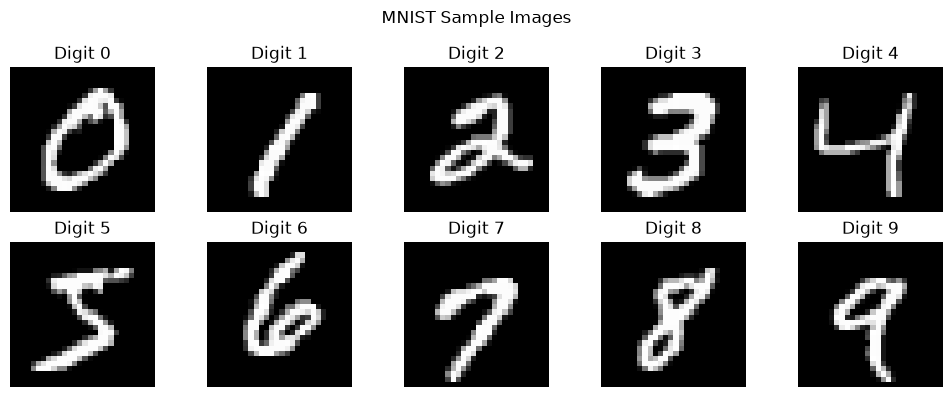

In [5]:
# 每个数字类别展示一个样本
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.ravel()):
    idx = (train_data.targets == digit).nonzero(as_tuple=True)[0][0]
    ax.imshow(train_data.data[idx], cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.suptitle("MNIST Sample Images")
plt.tight_layout()
plt.show()

In [6]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(784, 128)
        self.l2 = nn.Linear(128, 10)

    def forward(self, x):
        a1 = self.l1(x)
        x1 = F.relu(a1)
        a2 = self.l2(x1)
        return a2

model = MLP().to(device)
print(model)

MLP(
  (l1): Linear(in_features=784, out_features=128, bias=True)
  (l2): Linear(in_features=128, out_features=10, bias=True)
)


In [7]:
@torch.no_grad()
def evaluate(net, noise_std=0.0):
    """测试模型，返回损失、准确率和预测结果。"""
    net.eval()
    total_loss, correct = 0.0, 0
    labels, predictions, confidences = [], [], []

    for x, y in test_loader:
        if noise_std > 0:
            x = (x + noise_std * torch.randn_like(x)).clamp(0, 1)

        x = x.view(x.size(0), -1).to(device)
        y = y.to(device)

        output = net(x)
        total_loss += F.cross_entropy(
            output, y, reduction="sum"
        ).item()

        conf, pred = output.softmax(dim=1).max(dim=1)
        correct += (pred == y).sum().item()

        labels.append(y.cpu())
        predictions.append(pred.cpu())
        confidences.append(conf.cpu())

    n = len(test_loader.dataset)
    return {
        "loss": total_loss / n,
        "acc": correct / n,
        "true": torch.cat(labels).numpy(),
        "pred": torch.cat(predictions).numpy(),
        "conf": torch.cat(confidences).numpy()
    }


def fit(net, optimizer, n_epochs, name):
    """完整训练流程，并记录每轮损失。"""
    train_loader.generator.manual_seed(SEED)
    history = []
    start = perf_counter()

    for epoch in range(1, n_epochs + 1):
        net.train()
        total_loss = 0.0

        for x, y in train_loader:
            x = x.view(x.size(0), -1).to(device)
            y = y.to(device)

            optimizer.zero_grad()
            output = net(x)
            loss = F.cross_entropy(output, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)

        avg_loss = total_loss / len(train_loader.dataset)
        history.append(avg_loss)

        if epoch == 1 or epoch % 5 == 0 or epoch == n_epochs:
            print(f"{name} | Epoch {epoch:02d}/{n_epochs} "
                  f"| Train Loss: {avg_loss:.4f}")

    result = evaluate(net)
    elapsed = perf_counter() - start

    print(f"\n{name}")
    print(f"Test Loss: {result['loss']:.4f}")
    print(f"Test Accuracy: {result['acc']:.2%}")
    print(f"Training Time: {elapsed:.1f}s\n")

    return history, result, elapsed

In [8]:
torch.manual_seed(SEED)
model = MLP().to(device)

optimizer = optim.SGD(model.parameters(), lr=0.01)

base_hist, base_result, base_time = fit(
    model, optimizer, epochs, "Original MLP + SGD"
)

Original MLP + SGD | Epoch 01/30 | Train Loss: 2.2703
Original MLP + SGD | Epoch 05/30 | Train Loss: 1.9907
Original MLP + SGD | Epoch 10/30 | Train Loss: 1.4995
Original MLP + SGD | Epoch 15/30 | Train Loss: 1.0913
Original MLP + SGD | Epoch 20/30 | Train Loss: 0.8534
Original MLP + SGD | Epoch 25/30 | Train Loss: 0.7159
Original MLP + SGD | Epoch 30/30 | Train Loss: 0.6295

Original MLP + SGD
Test Loss: 0.5995
Test Accuracy: 86.26%
Training Time: 245.8s



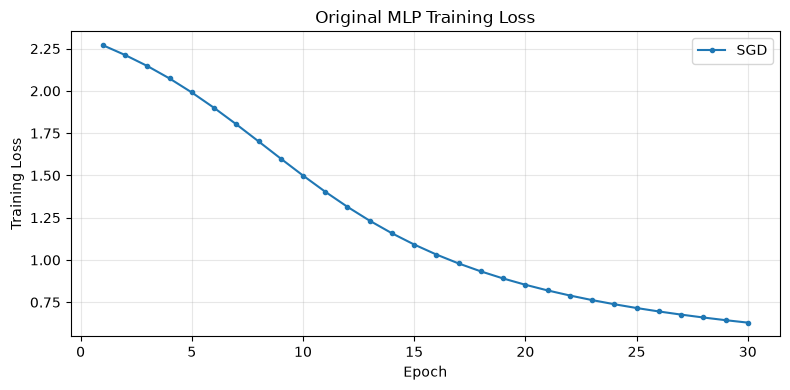

Final Test Accuracy: 86.26%


In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), base_hist, marker=".", label="SGD")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Original MLP Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final Test Accuracy: {base_result['acc']:.2%}")

Original MLP + Adam | Epoch 01/10 | Train Loss: 1.3952
Original MLP + Adam | Epoch 05/10 | Train Loss: 0.2844
Original MLP + Adam | Epoch 10/10 | Train Loss: 0.1962

Original MLP + Adam
Test Loss: 0.1941
Test Accuracy: 94.48%
Training Time: 85.2s



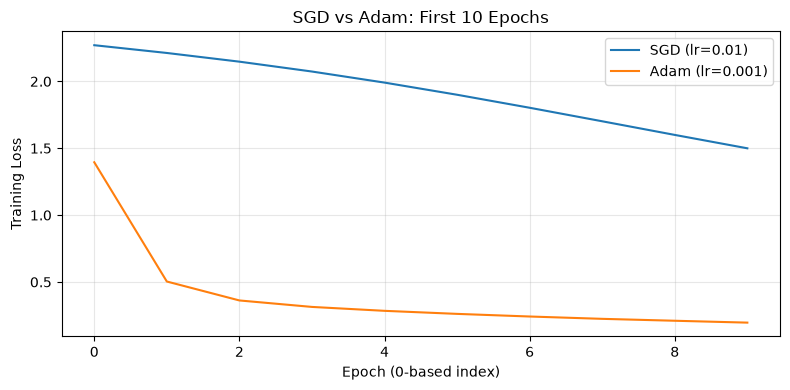

10轮训练损失对比
SGD:  1.4995
Adam: 0.1962


In [10]:
EXTRA_EPOCHS = 10

# 保持与基础模型相同的初始权重
torch.manual_seed(SEED)
adam_model = MLP().to(device)

adam_hist, adam_result, adam_time = fit(
    adam_model,
    optim.Adam(adam_model.parameters(), lr=0.001),
    EXTRA_EPOCHS,
    "Original MLP + Adam"
)

plt.figure(figsize=(8, 4))
plt.plot(base_hist[:10], label="SGD (lr=0.01)")
plt.plot(adam_hist, label="Adam (lr=0.001)")
plt.xlabel("Epoch (0-based index)")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam: First 10 Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("10轮训练损失对比")
print(f"SGD:  {base_hist[9]:.4f}")
print(f"Adam: {adam_hist[9]:.4f}")

In [11]:
class DeepMLP(nn.Module):
    def __init__(self, use_bn=True, dropout=0.3):
        super().__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 10)

        self.bn1 = nn.BatchNorm1d(256) if use_bn else nn.Identity()
        self.bn2 = nn.BatchNorm1d(128) if use_bn else nn.Identity()
        self.bn3 = nn.BatchNorm1d(64) if use_bn else nn.Identity()
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = self.drop(F.gelu(self.bn1(self.fc1(x))))
        x = self.drop(F.gelu(self.bn2(self.fc2(x))))
        x = F.gelu(self.bn3(self.fc3(x)))
        return self.fc4(x)

print(DeepMLP())

DeepMLP(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=10, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (drop): Dropout(p=0.3, inplace=False)
)


In [12]:
# 深层模型A：不使用BatchNorm和Dropout
torch.manual_seed(SEED)
deep_plain = DeepMLP(use_bn=False, dropout=0).to(device)

plain_hist, plain_result, plain_time = fit(
    deep_plain,
    optim.Adam(deep_plain.parameters(), lr=0.001),
    EXTRA_EPOCHS,
    "Deep MLP (No Regularization)"
)

# 深层模型B：同时使用BatchNorm和Dropout
torch.manual_seed(SEED)
deep_model = DeepMLP(use_bn=True, dropout=0.3).to(device)

deep_hist, deep_result, deep_time = fit(
    deep_model,
    optim.Adam(deep_model.parameters(), lr=0.001),
    EXTRA_EPOCHS,
    "Deep MLP + BN + Dropout"
)

Deep MLP (No Regularization) | Epoch 01/10 | Train Loss: 1.5425
Deep MLP (No Regularization) | Epoch 05/10 | Train Loss: 0.2123
Deep MLP (No Regularization) | Epoch 10/10 | Train Loss: 0.1155

Deep MLP (No Regularization)
Test Loss: 0.1215
Test Accuracy: 96.18%
Training Time: 85.3s

Deep MLP + BN + Dropout | Epoch 01/10 | Train Loss: 1.1637
Deep MLP + BN + Dropout | Epoch 05/10 | Train Loss: 0.1590
Deep MLP + BN + Dropout | Epoch 10/10 | Train Loss: 0.0766

Deep MLP + BN + Dropout
Test Loss: 0.0687
Test Accuracy: 97.97%
Training Time: 88.3s



Model                   Test Loss   Accuracy    Time(s)
MLP-SGD (30)               0.5995     86.26%      245.8
MLP-Adam (10)              0.1941     94.48%       85.2
Deep-NoReg (10)            0.1215     96.18%       85.3
Deep-BN+Drop (10)          0.0687     97.97%       88.3


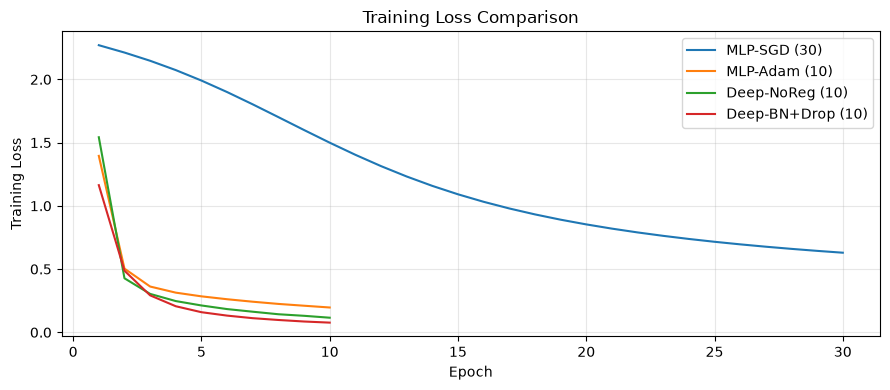

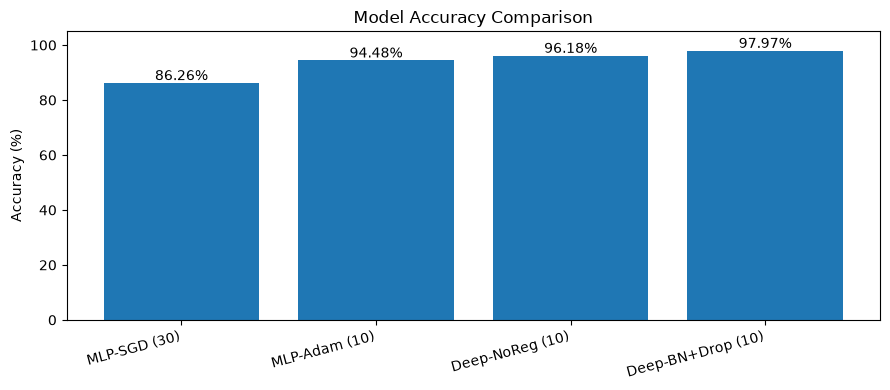

In [13]:
results = {
    "MLP-SGD (30)": (base_hist, base_result, base_time),
    "MLP-Adam (10)": (adam_hist, adam_result, adam_time),
    "Deep-NoReg (10)": (plain_hist, plain_result, plain_time),
    "Deep-BN+Drop (10)": (deep_hist, deep_result, deep_time)
}

print(f"{'Model':<22} {'Test Loss':>10} {'Accuracy':>10} {'Time(s)':>10}")
for name, (_, result, seconds) in results.items():
    print(f"{name:<22} {result['loss']:>10.4f} "
          f"{result['acc']*100:>9.2f}% {seconds:>10.1f}")

# 不同模型训练损失曲线
plt.figure(figsize=(9, 4))
for name, (hist, _, _) in results.items():
    plt.plot(range(1, len(hist) + 1), hist, label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 测试准确率柱状图
names = list(results.keys())
accs = [results[name][1]["acc"] * 100 for name in names]

plt.figure(figsize=(9, 4))
bars = plt.bar(range(len(names)), accs)
plt.xticks(range(len(names)), names, rotation=15, ha="right")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.title("Model Accuracy Comparison")

for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2, acc + 1,
             f"{acc:.2f}%", ha="center")

plt.tight_layout()
plt.show()

Macro Precision: 0.9798
Macro Recall:    0.9795
Macro F1-score:  0.9796


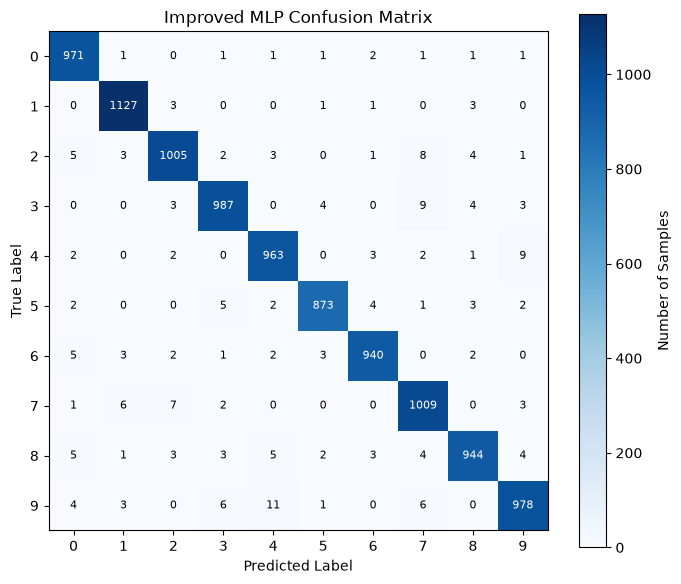

In [14]:
true = deep_result["true"]
pred = deep_result["pred"]

cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (true, pred), 1)

precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)
recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

print(f"Macro Precision: {precision.mean():.4f}")
print(f"Macro Recall:    {recall.mean():.4f}")
print(f"Macro F1-score:  {f1.mean():.4f}")

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Number of Samples")

for i in range(10):
    for j in range(10):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Improved MLP Confusion Matrix")
plt.tight_layout()
plt.show()

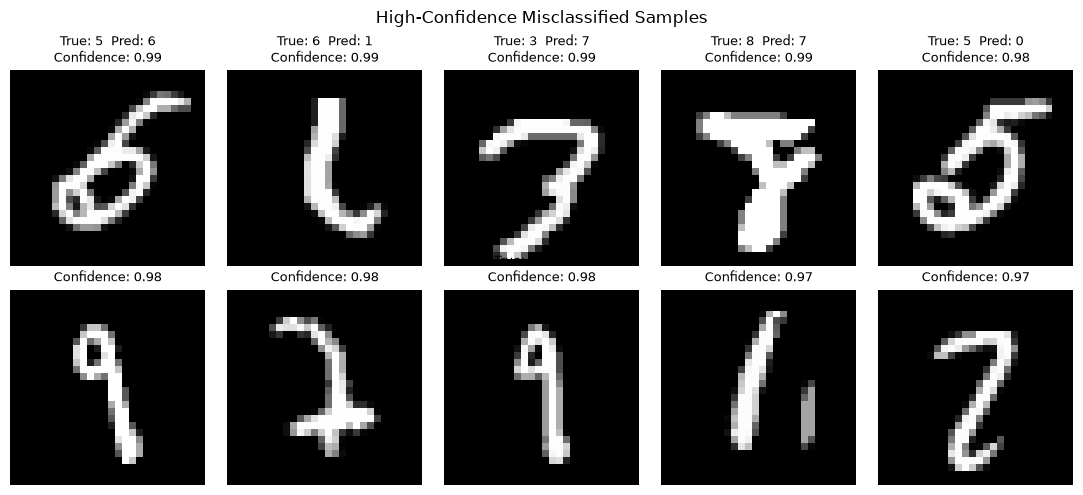

In [15]:
# 选取置信度最高的10张误分类图像
wrong = np.flatnonzero(true != pred)
wrong = wrong[np.argsort(-deep_result["conf"][wrong])][:10]

if len(wrong) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))

    for ax in axes.ravel():
        ax.axis("off")

    for ax, idx in zip(axes.ravel(), wrong):
        ax.imshow(test_data.data[int(idx)], cmap="gray")
        ax.set_title(
            f"True: {true[idx]}  Pred: {pred[idx]}\n"
            f"Confidence: {deep_result['conf'][idx]:.2f}",
            fontsize=9
        )

    plt.suptitle("High-Confidence Misclassified Samples")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified samples found.")

Original MLP (Adam) : ['94.48%', '91.77%', '71.63%', '53.85%', '32.91%']
Improved MLP : ['97.97%', '96.01%', '75.45%', '58.15%', '30.19%']


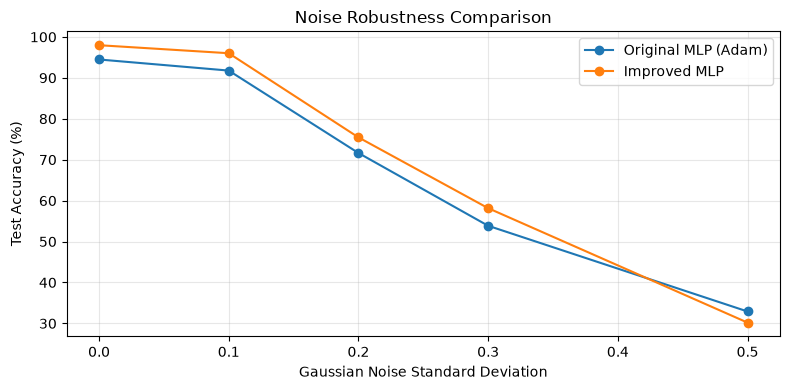

In [16]:
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.5]
robustness = {}

for name, net in [
    ("Original MLP (Adam)", adam_model),
    ("Improved MLP", deep_model)
]:
    accuracies = []

    for std in noise_levels:
        # 相同噪声强度下使用相同随机种子
        torch.manual_seed(SEED + int(std * 1000))
        result = evaluate(net, noise_std=std)
        accuracies.append(result["acc"] * 100)

    robustness[name] = accuracies
    print(name, ":", [f"{acc:.2f}%" for acc in accuracies])

plt.figure(figsize=(8, 4))

for name, accs in robustness.items():
    plt.plot(noise_levels, accs, marker="o", label=name)

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Test Accuracy (%)")
plt.title("Noise Robustness Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
rng = np.random.default_rng(SEED)
X = rng.normal(size=(5, 4))
W = rng.normal(scale=0.1, size=(4, 3))
y = np.array([0, 1, 2, 1, 0])

def softmax_loss(w):
    scores = X @ w
    scores -= scores.max(axis=1, keepdims=True)
    log_probs = scores - np.log(
        np.exp(scores).sum(axis=1, keepdims=True)
    )
    return -log_probs[np.arange(len(y)), y].mean()

# 解析梯度
scores = X @ W
prob = np.exp(scores - scores.max(axis=1, keepdims=True))
prob /= prob.sum(axis=1, keepdims=True)
prob[np.arange(len(y)), y] -= 1

analytic_grad = X.T @ (prob / len(y))

# 中心差分：验证 W[0,0]
h = 1e-5
W[0, 0] += h
loss_plus = softmax_loss(W)

W[0, 0] -= 2 * h
loss_minus = softmax_loss(W)

W[0, 0] += h
numeric_grad = (loss_plus - loss_minus) / (2 * h)

relative_error = abs(numeric_grad - analytic_grad[0, 0]) / max(
    1e-12, abs(numeric_grad) + abs(analytic_grad[0, 0])
)

print(f"Analytical Gradient: {analytic_grad[0, 0]:.8f}")
print(f"Numerical Gradient:  {numeric_grad:.8f}")
print(f"Relative Error:      {relative_error:.2e}")
print("Gradient Check:", "PASS" if relative_error < 1e-5 else "CHECK")

Analytical Gradient: -0.22324866
Numerical Gradient:  -0.22324866
Relative Error:      8.72e-12
Gradient Check: PASS
